<a href="https://www.pieriandata.com"><img src="data/Logo.jpg"></a>
*Copyright by Pierian Data Inc.*

# Contour Detection

## External vs Internal Contours

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
img = cv2.imread('data/internal_external.png',0)

In [3]:
img.shape

(652, 1080)

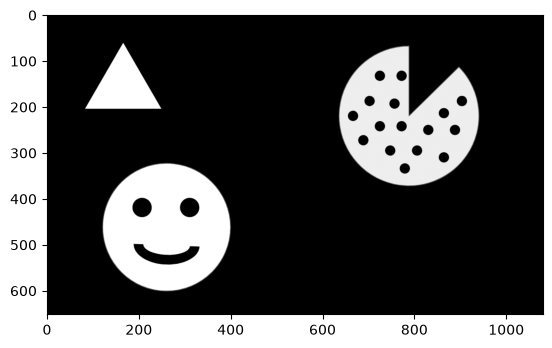

In [4]:
plt.imshow(img, cmap='gray')

**findContours**

function will return back contours in an image, and based on the RETR method called, you can get back external, internal, or both:

* cv2.RETR_EXTERNAL:Only extracts external contours
* cv2.RETR_CCOMP: Extracts both internal and external contours organized in a two-level hierarchy
* cv2.RETR_TREE: Extracts both internal and external contours organized in a  tree graph
* cv2.RETR_LIST: Extracts all contours without any internal/external relationship

---

**`mode = cv2.RETR_CCOMP`**  
Specifies how OpenCV retrieves and organizes contours. `RETR_CCOMP` arranges contours into a two-level hierarchy:
- **Level 1**: outer contours of objects.
- **Level 2**: contours of holes inside objects.  
For example, the outer boundary of a ring is an **external** contour, while the boundary of its hole is a **child** contour.

---

**`method = cv2.CHAIN_APPROX_SIMPLE`**  
Specifies how contour points are stored. It removes redundant intermediate points along straight lines.  
For example, instead of storing every pixel along the four sides of a rectangle, OpenCV can represent its outline using just the four corner points. This saves memory while preserving the contour's shape.


In [5]:
contours, hierarchy = cv2.findContours(image = img,
                                       mode = cv2.RETR_CCOMP,
                                       method = cv2.CHAIN_APPROX_SIMPLE)

In [6]:
type(contours), len(contours)

(tuple, 22)

In [7]:
type(hierarchy), hierarchy.shape

(numpy.ndarray, (1, 22, 4))

In [8]:
hierarchy

array([[[ 4, -1,  1, -1],
        [ 2, -1, -1,  0],
        [ 3,  1, -1,  0],
        [-1,  2, -1,  0],
        [21,  0,  5, -1],
        [ 6, -1, -1,  4],
        [ 7,  5, -1,  4],
        [ 8,  6, -1,  4],
        [ 9,  7, -1,  4],
        [10,  8, -1,  4],
        [11,  9, -1,  4],
        [12, 10, -1,  4],
        [13, 11, -1,  4],
        [14, 12, -1,  4],
        [15, 13, -1,  4],
        [16, 14, -1,  4],
        [17, 15, -1,  4],
        [18, 16, -1,  4],
        [19, 17, -1,  4],
        [20, 18, -1,  4],
        [-1, 19, -1,  4],
        [-1,  4, -1, -1]]], dtype=int32)

**Draw both external and child contours**

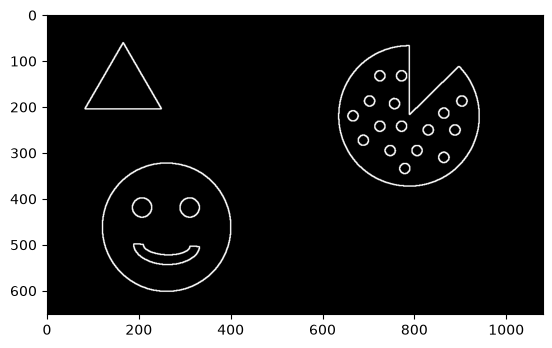

In [9]:
all_contours = np.zeros(img.shape)

# For every entry in contours
for i in range(len(contours)):

    # Draw contours
    cv2.drawContours(image = all_contours, 
                     contours = contours, 
                     contourIdx = i, 
                     color = 255, 
                     thickness = 2)

# Show the image
plt.imshow(all_contours, cmap='gray')

**Draw only external contours**

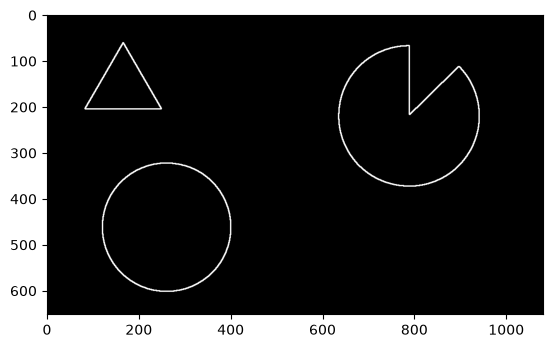

In [10]:
ext_contours = np.zeros(img.shape) 

# For every entry in contours
for i in range(len(contours)):

    # Last column in the array is -1 if an external contour (no contours inside of it)
    if hierarchy[0][i][3] == -1:
        
        # Draw contours
        cv2.drawContours(image = ext_contours, 
                         contours = contours, 
                         contourIdx = i, 
                         color = 255, 
                         thickness = 2)
        
# Show the image      
plt.imshow(ext_contours, cmap='gray')

**Draw only internal (child) contours**

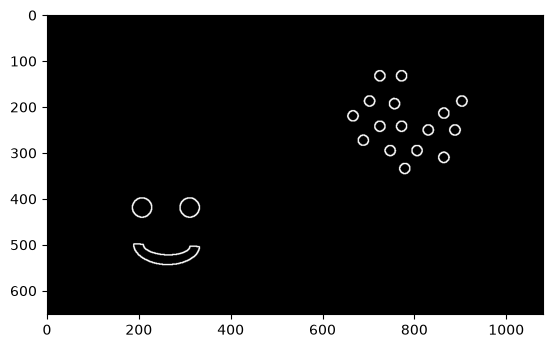

In [11]:
int_contours = np.zeros(img.shape) 

# For every entry in contours
for i in range(len(contours)):

    # Last column in the array is -1 if an external contour (no contours inside of it)
    if hierarchy[0][i][3] != -1:
        
        # Draw contours
        cv2.drawContours(image = int_contours, 
                         contours = contours, 
                         contourIdx = i, 
                         color = 255, 
                         thickness = 2)
        
# Show the image      
plt.imshow(int_contours, cmap='gray')

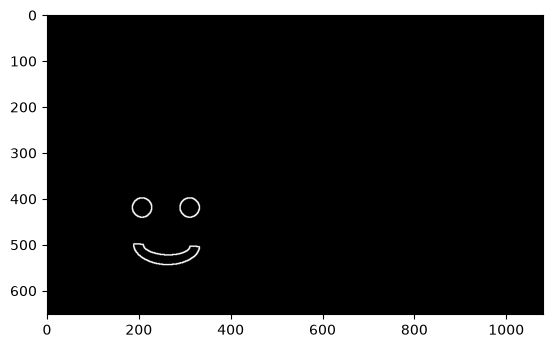

In [12]:
int_contours = np.zeros(img.shape) 

# For every entry in contours
for i in range(len(contours)):

    # Last column in the array is -1 if an external contour (no contours inside of it)
    if hierarchy[0][i][3] == 0:
        
        # Draw contours
        cv2.drawContours(image = int_contours, 
                         contours = contours, 
                         contourIdx = i, 
                         color = 255, 
                         thickness = 2)
        
# Show the image      
plt.imshow(int_contours, cmap='gray')

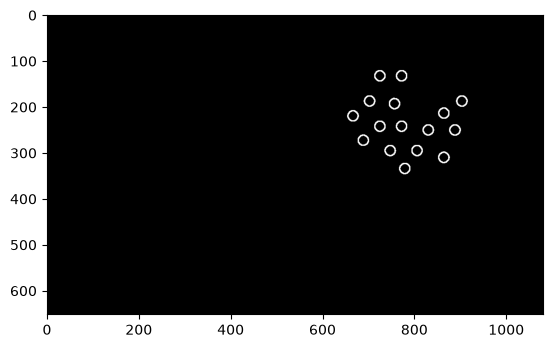

In [13]:
int_contours = np.zeros(img.shape) 

# For every entry in contours
for i in range(len(contours)):

    # Last column in the array is -1 if an external contour (no contours inside of it)
    if hierarchy[0][i][3] == 4:
        
        # Draw contours
        cv2.drawContours(image = int_contours, 
                         contours = contours, 
                         contourIdx = i, 
                         color = 255, 
                         thickness = 2)
        
# Show the image      
plt.imshow(int_contours, cmap='gray')